In [1]:
!pip install -q scikeras tensorflow scikit-learn pandas matplotlib seaborn

In [2]:
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

from scikeras.wrappers import KerasClassifier
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")

SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [3]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["Outcome"].value_counts())

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Summary statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


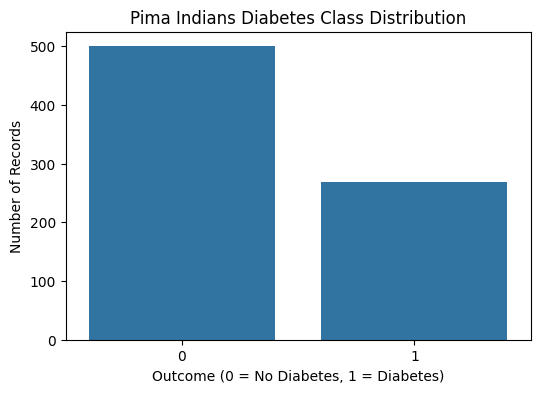

In [5]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Outcome")

plt.title("Pima Indians Diabetes Class Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Records")

plt.show()

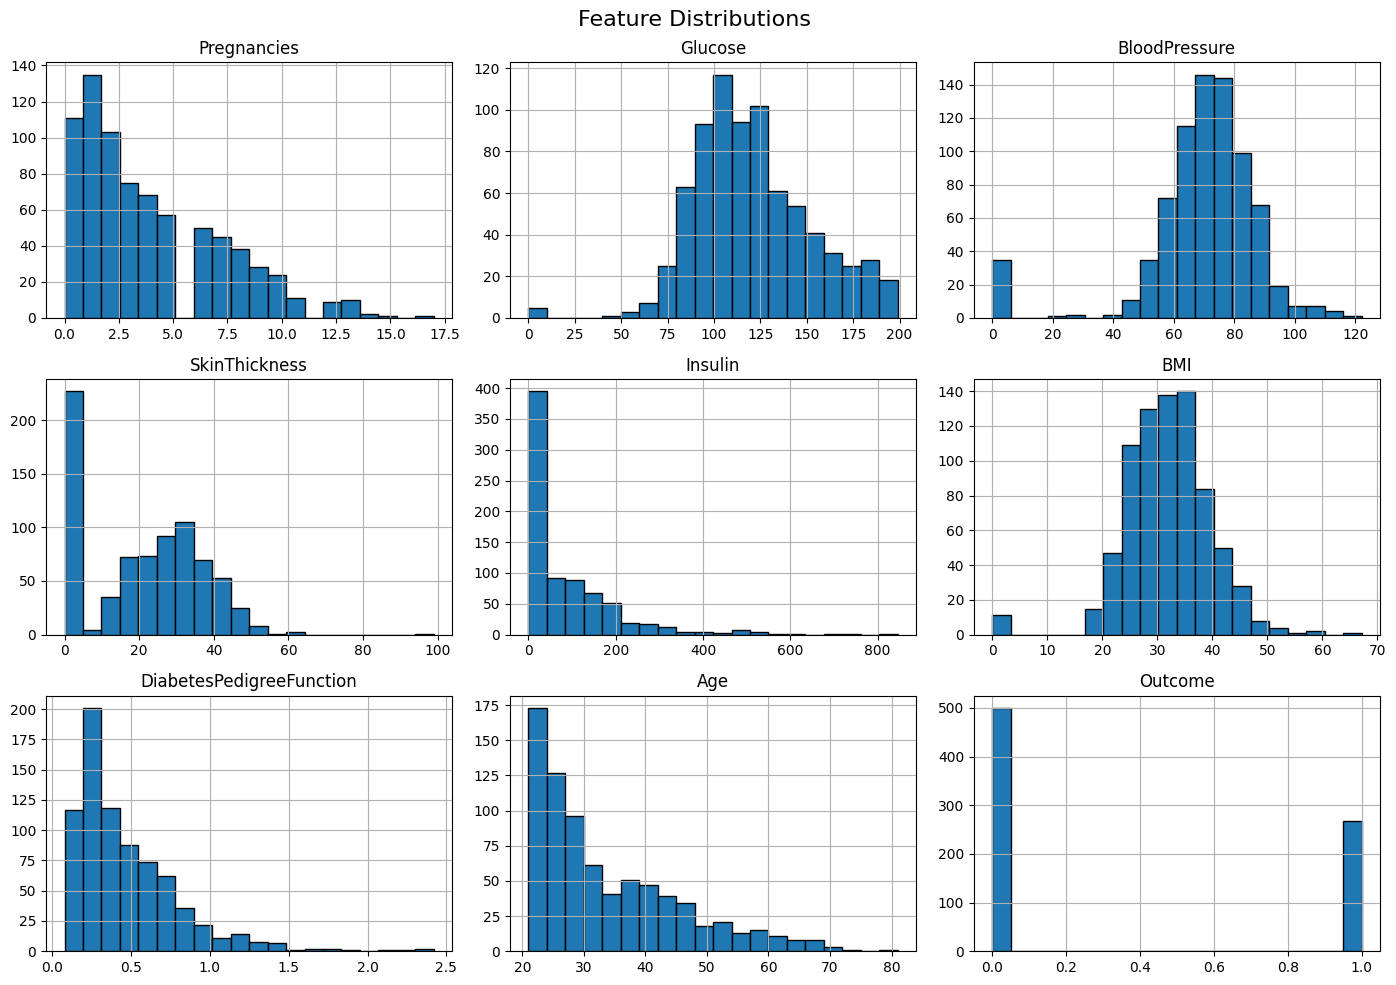

In [6]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black")

plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

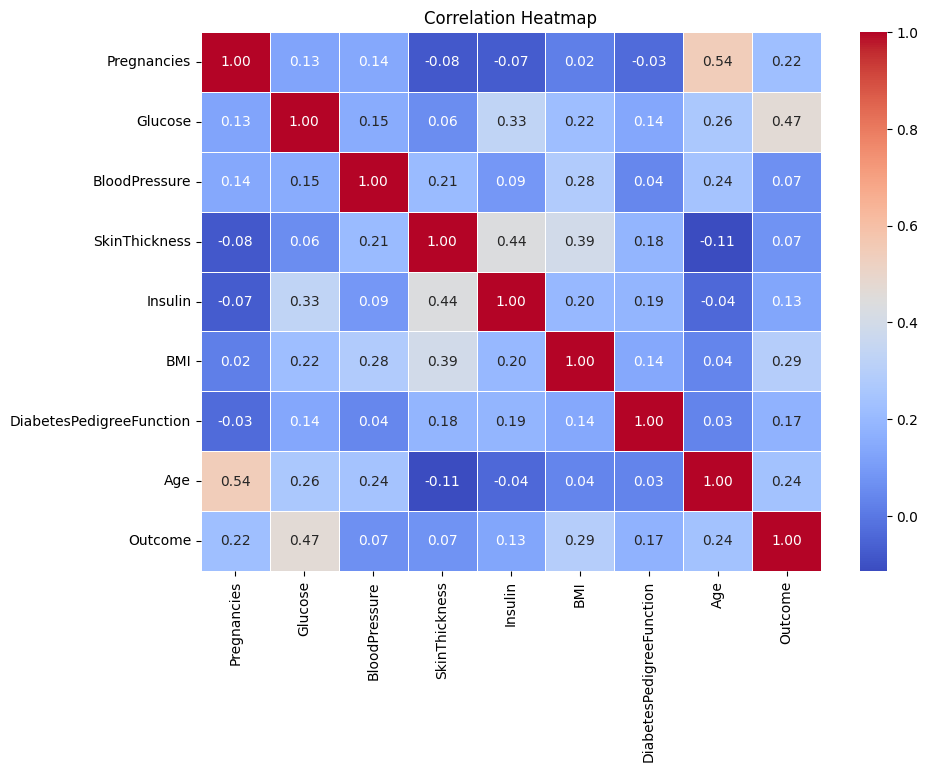

In [7]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

In [8]:
df_clean = df.copy()

invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for column in invalid_zero_columns:
    df_clean[column] = df_clean[column].replace(0, np.nan)

print("Missing values after handling invalid zeros:")
print(df_clean.isnull().sum())

Missing values after handling invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [9]:
for column in invalid_zero_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

print("Missing values after imputation:")
print(df_clean.isnull().sum())

print("Remaining duplicates:", df_clean.duplicated().sum())

Missing values after imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Remaining duplicates: 0


In [10]:
X = df_clean.drop(columns=["Outcome"])
y = df_clean["Outcome"].astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Feature shape: (768, 8)
Target shape: (768,)

Target classes:
Outcome
0    500
1    268
Name: count, dtype: int64


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))

Training samples: 614
Testing samples: 154
Training class proportions:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing class proportions:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [33]:
def build_model(
    meta,
    neurons=16,
    activation="relu",
    dropout_rate=0.2,
    learning_rate=0.001,
    kernel_initializer="glorot_uniform"
):
    model = Sequential([
        Input(shape=(meta["n_features_in_"],)),

        Dense(
            units=neurons,
            activation=activation,
            kernel_initializer=kernel_initializer
        ),

        Dropout(dropout_rate),

        Dense(
            units=1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [34]:

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np
import tensorflow as tf

class DiabetesKerasClassifier(ClassifierMixin, BaseEstimator):

    def __init__(
        self,
        neurons=16,
        activation="relu",
        dropout_rate=0.2,
        learning_rate=0.001,
        kernel_initializer="glorot_uniform",
        batch_size=32,
        epochs=30,
        random_state=42
    ):
        self.neurons = neurons
        self.activation = activation
        self.dropout_rate = dropout_rate
        self.learning_rate = learning_rate
        self.kernel_initializer = kernel_initializer
        self.batch_size = batch_size
        self.epochs = epochs
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.int32)

        self.classes_ = np.unique(y)
        tf.keras.utils.set_random_seed(self.random_state)

        tf.keras.backend.clear_session()

        self.model_ = build_model(
            meta={"n_features_in_": X.shape[1]},
            neurons=self.neurons,
            activation=self.activation,
            dropout_rate=self.dropout_rate,
            learning_rate=self.learning_rate,
            kernel_initializer=self.kernel_initializer
        )

        self.model_.fit(
            X,
            y,
            batch_size=self.batch_size,
            epochs=self.epochs,
            verbose=0
        )

        self.n_features_in_ = X.shape[1]
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float32)
        positive_probability = self.model_.predict(
            X, verbose=0
        ).ravel()

        return np.column_stack([
            1 - positive_probability,
            positive_probability
        ])

    def predict(self, X):
        probabilities = self.predict_proba(X)[:, 1]
        return (probabilities >= 0.5).astype(int)


In [35]:

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", DiabetesKerasClassifier(random_state=SEED))
])

print("Custom classifier pipeline created.")
print("Classifier:", type(pipeline.named_steps["clf"]).__name__)


Custom classifier pipeline created.
Classifier: DiabetesKerasClassifier


In [36]:

baseline = {
    "clf__batch_size": [32],
    "clf__epochs": [30],
    "clf__learning_rate": [0.001],
    "clf__kernel_initializer": ["glorot_uniform"],
    "clf__activation": ["relu"],
    "clf__dropout_rate": [0.2],
    "clf__neurons": [16]
}

param_grid = [
    baseline,
    {**baseline, "clf__batch_size": [16]},
    {**baseline, "clf__epochs": [50]},
    {**baseline, "clf__learning_rate": [0.01]},
    {**baseline, "clf__kernel_initializer": ["he_normal"]},
    {**baseline, "clf__activation": ["tanh"]},
    {**baseline, "clf__dropout_rate": [0.0]},
    {**baseline, "clf__dropout_rate": [0.4]},
    {**baseline, "clf__neurons": [32]},
    {**baseline, "clf__neurons": [64]}
]

print("Configurations:", len(param_grid))


Configurations: 10


In [37]:

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    refit=True,
    n_jobs=1,
    verbose=2,
    error_score="raise",
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("\nGrid search completed successfully!")
print("Best CV ROC-AUC:", grid_search.best_score_)
print("\nBest parameters:")

for parameter, value in grid_search.best_params_.items():
    print(f"{parameter}: {value}")


Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END clf__activation=relu, clf__batch_size=32, clf__dropout_rate=0.2, clf__epochs=30, clf__kernel_initializer=glorot_uniform, clf__learning_rate=0.001, clf__neurons=16; total time=   4.2s
[CV] END clf__activation=relu, clf__batch_size=32, clf__dropout_rate=0.2, clf__epochs=30, clf__kernel_initializer=glorot_uniform, clf__learning_rate=0.001, clf__neurons=16; total time=   4.1s
[CV] END clf__activation=relu, clf__batch_size=32, clf__dropout_rate=0.2, clf__epochs=30, clf__kernel_initializer=glorot_uniform, clf__learning_rate=0.001, clf__neurons=16; total time=   4.1s
[CV] END clf__activation=relu, clf__batch_size=16, clf__dropout_rate=0.2, clf__epochs=30, clf__kernel_initializer=glorot_uniform, clf__learning_rate=0.001, clf__neurons=16; total time=   5.7s
[CV] END clf__activation=relu, clf__batch_size=16, clf__dropout_rate=0.2, clf__epochs=30, clf__kernel_initializer=glorot_uniform, clf__learning_rate=0.001, clf__neurons=16

In [38]:
results_df = pd.DataFrame(grid_search.cv_results_)

results_df = results_df.sort_values(
    by="mean_test_score",
    ascending=False
)

columns_to_show = [
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "rank_test_score",
    "params"
]

display(results_df[columns_to_show].reset_index(drop=True))

,mean_test_score,std_test_score,mean_train_score,rank_test_score,params
0,0.846846,0.019991,0.879421,1,"{'clf__activation': 'relu', 'clf__batch_size':..."
1,0.843070,0.022140,0.867983,2,"{'clf__activation': 'relu', 'clf__batch_size':..."
2,0.841278,0.020932,0.865871,3,"{'clf__activation': 'relu', 'clf__batch_size':..."
3,0.838708,0.017116,0.849769,4,"{'clf__activation': 'tanh', 'clf__batch_size':..."
4,0.837633,0.019623,0.862604,5,"{'clf__activation': 'relu', 'clf__batch_size':..."
5,0.836291,0.022297,0.897870,6,"{'clf__activation': 'relu', 'clf__batch_size':..."
6,0.834874,0.020273,0.852634,7,"{'clf__activation': 'relu', 'clf__batch_size':..."
7,0.834310,0.024122,0.851070,8,"{'clf__activation': 'relu', 'clf__batch_size':..."
8,0.832559,0.019233,0.847448,9,"{'clf__activation': 'relu', 'clf__batch_size':..."
9,0.808858,0.011702,0.832063,10,"{'clf__activation': 'relu', 'clf__batch_size':..."


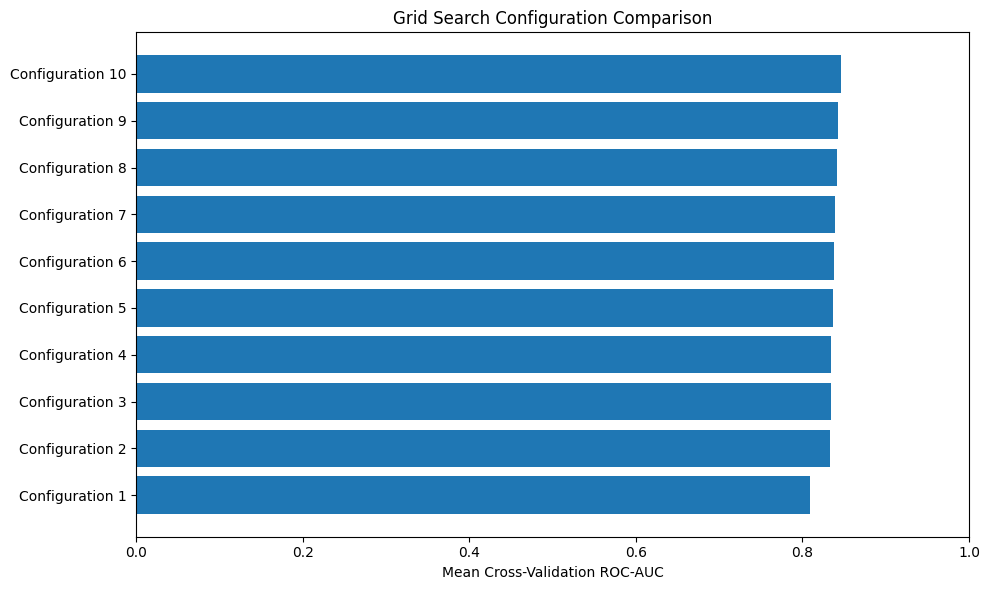

In [39]:
plot_df = results_df.sort_values("mean_test_score")

plt.figure(figsize=(10, 6))

plt.barh(
    range(len(plot_df)),
    plot_df["mean_test_score"]
)

plt.yticks(
    range(len(plot_df)),
    [f"Configuration {i+1}" for i in range(len(plot_df))]
)

plt.xlabel("Mean Cross-Validation ROC-AUC")
plt.title("Grid Search Configuration Comparison")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [40]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

y_prob = best_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print("FINAL TEST RESULTS")
print("=" * 40)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

FINAL TEST RESULTS
Accuracy : 0.7273
Precision: 0.6154
Recall   : 0.5926
F1-score : 0.6038
ROC-AUC  : 0.8165


In [41]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.78      0.80      0.79       100
    Diabetes       0.62      0.59      0.60        54

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154



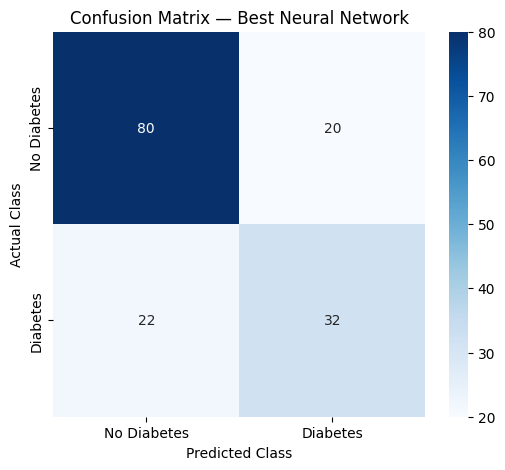

Confusion matrix:
[[80 20]
 [22 32]]


In [42]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix — Best Neural Network")

plt.show()

print("Confusion matrix:")
print(cm)

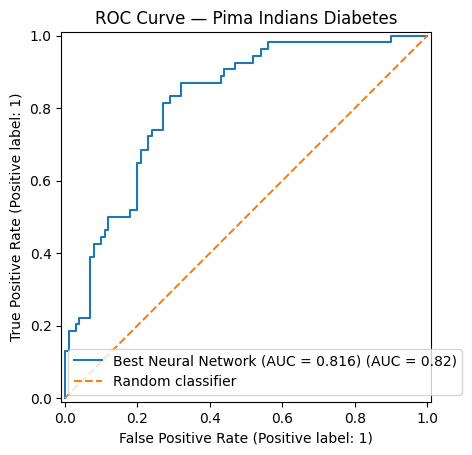

In [43]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name=f"Best Neural Network (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.title("ROC Curve — Pima Indians Diabetes")
plt.legend()
plt.show()

In [45]:
final_summary = pd.DataFrame([{
    "Best CV ROC-AUC": grid_search.best_score_,
    "Test Accuracy": accuracy,
    "Test Precision": precision,
    "Test Recall": recall,
    "Test F1-score": f1,
    "Test ROC-AUC": auc,
    "Best Batch Size": grid_search.best_params_["clf__batch_size"],
    "Best Epochs": grid_search.best_params_["clf__epochs"],
    "Best Learning Rate": grid_search.best_params_["clf__learning_rate"],
    "Best Initializer": grid_search.best_params_["clf__kernel_initializer"],
    "Best Activation": grid_search.best_params_["clf__activation"],
    "Best Dropout": grid_search.best_params_["clf__dropout_rate"],
    "Best Hidden Neurons": grid_search.best_params_["clf__neurons"]
}])

display(final_summary)

,Best CV ROC-AUC,Test Accuracy,Test Precision,Test Recall,Test F1-score,Test ROC-AUC,Best Batch Size,Best Epochs,Best Learning Rate,Best Initializer,Best Activation,Best Dropout,Best Hidden Neurons
0,0.846846,0.727273,0.615385,0.592593,0.603774,0.816481,32,30,0.001,glorot_uniform,relu,0.2,64


In [46]:
results_df.to_csv(
    "/content/grid_search_results.csv",
    index=False
)

final_summary.to_csv(
    "/content/final_model_summary.csv",
    index=False
)

# Save the fitted Keras neural network inside the pipeline
best_model.named_steps["clf"].model_.save(
    "/content/best_diabetes_model.keras"
)

print("Saved:")
print("- /content/grid_search_results.csv")
print("- /content/final_model_summary.csv")
print("- /content/best_diabetes_model.keras")

Saved:
- /content/grid_search_results.csv
- /content/final_model_summary.csv
- /content/best_diabetes_model.keras
